# Adiabatic interface-temperature comparison

This notebook compares the two adiabatic interface-temperature treatments now available in `solve_front_adiabatic`:

- **Legacy T_const:** `interface_temperature_mode='T_const'`, where the interface quark state uses `T(0+) = T(0-)`.
- **New hu_const condition:** `interface_temperature_mode='hu_const'`, where the interface quark temperature is solved so that `[hu] = 0` across `x=0`.

The first code cell runs both solvers with the same upstream state and stores full profiles. The following visualization cell overlays the profiles and adds an enthalpy-focused diagnostic for the jump condition.


## Calculation cell

This cell runs the legacy and new adiabatic solvers on the same trial input.

What it does:
- Sets the shared upstream nuclear state and solver controls.
- Runs `solve_front_adiabatic` once in legacy temperature-continuity mode.
- Runs `solve_front_adiabatic` once in new enthalpy-jump mode.
- Checks that both returned the profile fields needed by the plot cell.
- Stores the outputs in `res_adiabatic_legacy_trial`, `res_adiabatic_jump_trial`, and `adiabatic_mode_results`.

Notes:
- This cell can take a little while because it solves two nonlinear compact BVPs.
- The plotting cell below assumes this cell has already been run.


In [12]:
# ADIABATIC_LEGACY_JUMP_PROFILE_CALC
# Run the legacy and enthalpy-jump adiabatic solvers on the same input.

import numpy as np

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import solve_front_adiabatic

# Shared trial inputs, kept close to the recent adiabatic comparison notebooks.
n0 = 0.16 * const.MeV_fm**3
T_compare_trial = 10
nB_N_compare_trial = 3.0 * n0
B14_compare_trial = 180.0
ms_compare_trial = 0.0
aQstar_compare_trial = 0.3
NM_type_compare_trial = 'PNM'
param_compare_trial = para.paraQMCRMF3

# BVP controls.
tail_eps_compare_trial = 1.0e-6
n_mesh_compare_trial = 40
tol_compare_trial = 1.0e-6
max_nodes_compare_trial = 1200
jB_guess_compare_trial = None
TQ_guess_compare_trial = 80
jB_bounds_compare_trial = (1.0e-5, 5.0)

common_adiabatic_kwargs = dict(
    T=T_compare_trial,
    nB_N=nB_N_compare_trial,
    B_one_forth=B14_compare_trial,
    aQstar=aQstar_compare_trial,
    ms=ms_compare_trial,
    param=param_compare_trial,
    NM_type=NM_type_compare_trial,
    tail_eps=tail_eps_compare_trial,
    n_mesh=n_mesh_compare_trial,
    tol_bvp=tol_compare_trial,
    max_nodes=max_nodes_compare_trial,
    jB_guess=jB_guess_compare_trial,
    TQ_guess=TQ_guess_compare_trial,
    jB_bounds=jB_bounds_compare_trial,
    return_profile=True,
    verb=False,
)

res_adiabatic_legacy_trial = solve_front_adiabatic(
    **common_adiabatic_kwargs,
    interface_temperature_mode='T_const',
)
res_adiabatic_jump_trial = solve_front_adiabatic(
    **common_adiabatic_kwargs,
    interface_temperature_mode='hu_const',
)

adiabatic_mode_results = {
    'legacy': res_adiabatic_legacy_trial,
    'hu_const': res_adiabatic_jump_trial,
}

required_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile',
    'T_N', 'T_Q', 'T_Qstar', 'h_over_nB_N', 'h_over_nB_Qstar',
    'h_over_nB_jump_residual', 'interface_temperature_mode',
]
for mode_label, result in adiabatic_mode_results.items():
    missing_keys = [key for key in required_profile_keys if key not in result]
    if missing_keys:
        raise RuntimeError(
            f'{mode_label} result is missing required profile keys: '
            + ', '.join(missing_keys)
        )
    if not bool(result.get('success')):
        raise RuntimeError(
            f'{mode_label} adiabatic solve failed: {result.get("message", "")}'
        )

print('Adiabatic interface-temperature comparison:')
print(f'  T_N: {T_compare_trial:.8g} MeV')
print(f'  nB_N: {nB_N_compare_trial / n0:.6g} n0')
print(f'  B^(1/4): {B14_compare_trial:.6g} MeV')
print(f'  aQstar: {aQstar_compare_trial:.6g}')
for mode_label, result in adiabatic_mode_results.items():
    print(f'\n{mode_label.upper()} mode:')
    print(f"  solver mode: {result.get('interface_temperature_mode')}")
    print(f"  success: {result.get('success')}")
    print(f"  message: {result.get('message', '')}")
    print(f"  jB: {result.get('jB', np.nan):.8g}")
    print(f"  T_Q: {result.get('T_Q', np.nan):.8g} MeV")
    print(f"  T_Qstar: {result.get('T_Qstar', np.nan):.8g} MeV")
    print(f"  h/nB jump residual: {result.get('h_over_nB_jump_residual', np.nan):.8g} MeV")
    print(f"  tail_norm: {result.get('tail_residual_norm', np.nan):.8g}")
    print(f"  entropy_tail_norm: {result.get('entropy_tail_residual_norm', np.nan):.8g}")


Adiabatic interface-temperature comparison:
  T_N: 10 MeV
  nB_N: 3 n0
  B^(1/4): 180 MeV
  aQstar: 0.3

LEGACY mode:
  solver mode: T_const
  success: True
  message: Adiabatic compact BVP steady-front solve converged
  jB: 0.58353835
  T_Q: 20.018579 MeV
  T_Qstar: 10 MeV
  h/nB jump residual: -24.441573 MeV
  tail_norm: -2.9742423e-13
  entropy_tail_norm: -1.2945453e-13

HU_CONST mode:
  solver mode: hu_const
  success: True
  message: Adiabatic compact BVP steady-front solve converged
  jB: 0.51088974
  T_Q: 32.228756 MeV
  T_Qstar: 27.185479 MeV
  h/nB jump residual: 0 MeV
  tail_norm: -2.4999905e-13
  entropy_tail_norm: -2.8190811e-13


## Visualization cell

This cell overlays the legacy and enthalpy-jump adiabatic profiles.

The first figure follows the style of the recent profile comparison cells: it shows `a(x)`, velocity, density, chemical potentials, and temperature across the boundary. Dashed segments at `x<0` mark the upstream nuclear state.

The second figure focuses on the new jump condition. It compares `hu`, `h`, and `h u`; in the new mode, the interface value of `hu` is solved to match the upstream nuclear value.


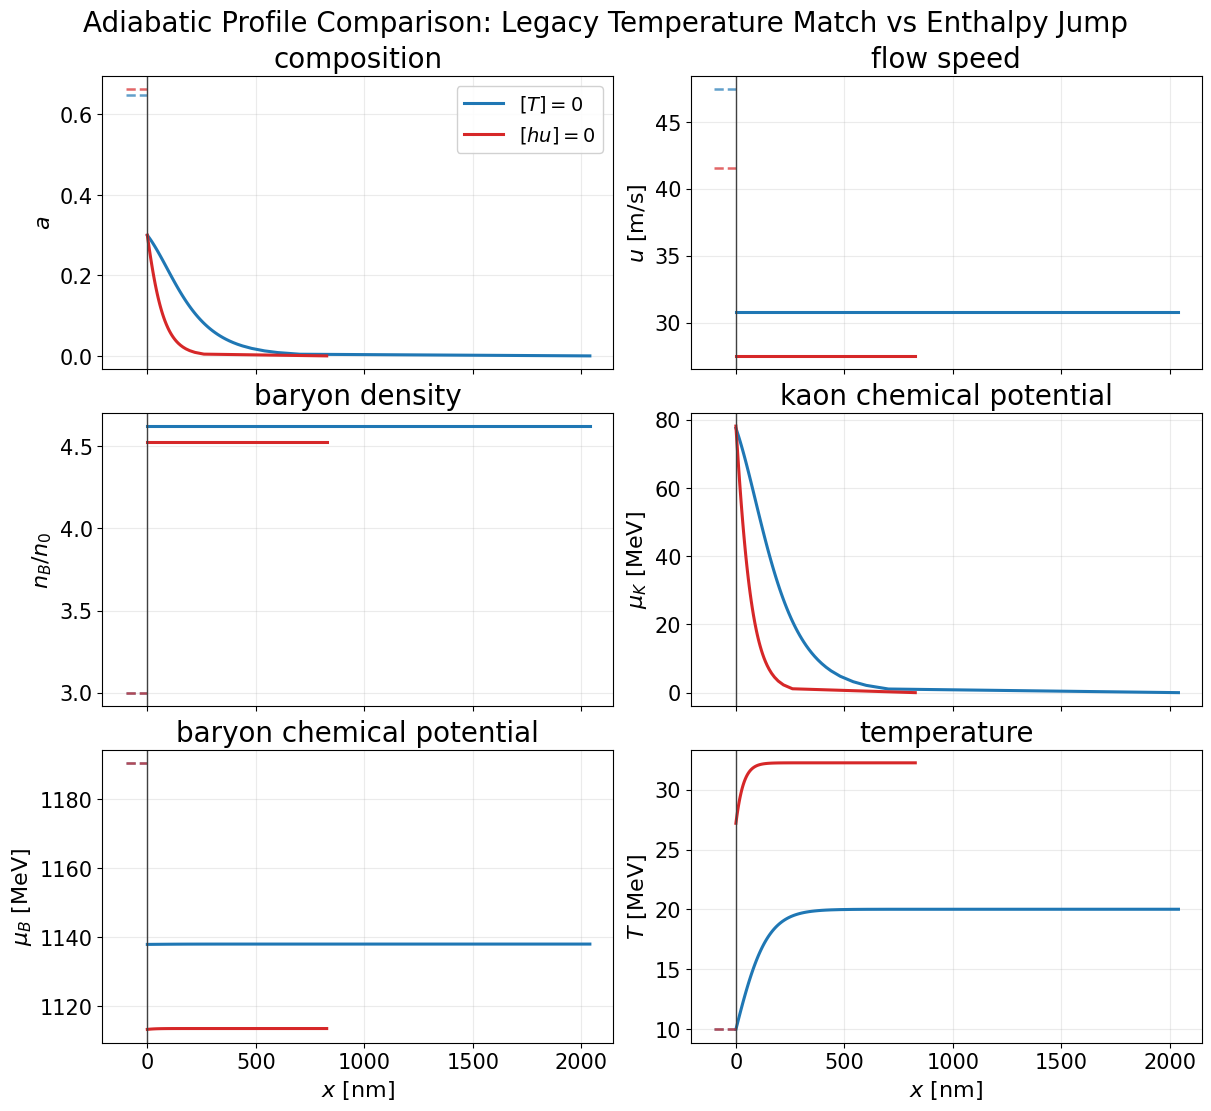

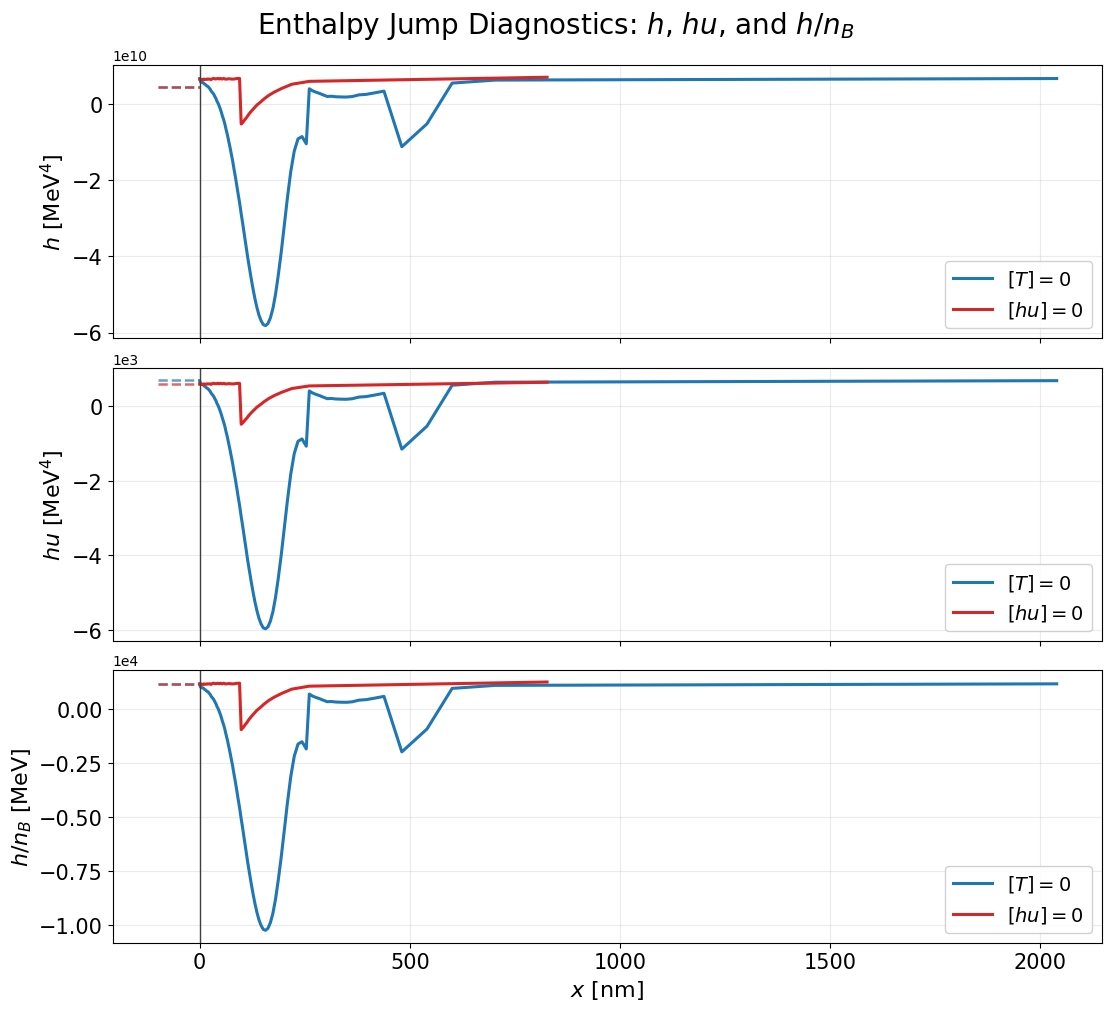

$[T]=0$: h/nB jump residual=-2.444157e+01 MeV, interface hu relative mismatch=-1.302216e-02
$[hu]=0$: h/nB jump residual=0.000000e+00 MeV, interface hu relative mismatch=-2.924083e-03


In [14]:
# VISUALIZE_ADIABATIC_PROFILE_COMPARISON
# Overlay the legacy and enthalpy-jump adiabatic profiles.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.SQMsolver import PQM
from RMFsolver.phase_velocity import PNM_n, edensNM_n, _solve_scalar_root, nB_NM

required_profile_plot_names = [
    'res_adiabatic_legacy_trial',
    'res_adiabatic_jump_trial',
    'T_compare_trial',
    'nB_N_compare_trial',
    'B14_compare_trial',
    'ms_compare_trial',
]
missing_profile_plot_names = [name for name in required_profile_plot_names if name not in globals()]
if missing_profile_plot_names:
    raise RuntimeError(
        'Run the ADIABATIC_LEGACY_JUMP_PROFILE_CALC cell first. Missing names: '
        + ', '.join(missing_profile_plot_names)
    )

profile_plot_modes = [
    (r'$[T]=0$', res_adiabatic_legacy_trial, 'C0'),
    (r'$[hu]=0$', res_adiabatic_jump_trial, 'C3'),
]


def _quark_pressure_profile(result):
    muB_values = np.asarray(result['muB'], dtype=float)
    muK_values = np.asarray(result['muK'], dtype=float)
    T_values = np.asarray(result['T_profile'], dtype=float)
    P_values = np.empty_like(muB_values)
    for i, (muB_value, muK_value, T_value) in enumerate(zip(muB_values, muK_values, T_values)):
        P_values[i] = PQM(
            float(muB_value),
            float(muK_value),
            B14_compare_trial,
            float(T_value),
            ms=ms_compare_trial,
        )
    return P_values


def _adiabatic_plot_profile(result):
    x_nm = np.asarray(result['x'], dtype=float) * const.MeV_fm / 1.0e6
    a_values = np.asarray(result['a'], dtype=float)
    u_values = np.asarray(result['u'], dtype=float)
    nB_values = np.asarray(result['nB'], dtype=float)
    muB_values = np.asarray(result['muB'], dtype=float)
    muK_values = np.asarray(result['muK'], dtype=float)
    T_values = np.asarray(result['T_profile'], dtype=float)
    w_values = np.asarray(result['w'], dtype=float)
    P_values = _quark_pressure_profile(result)
    h_values = (float(result['Pi']) - P_values) / np.maximum(u_values * u_values, np.finfo(float).tiny)
    hu_values = h_values * u_values
    return {
        'x_nm': x_nm,
        'a': a_values,
        'u_m_s': u_values * const.m_per_sec,
        'nB_over_n0': nB_values / n0,
        'muB': muB_values,
        'muK': muK_values,
        'T': T_values,
        'w': w_values,
        'h': h_values,
        'hu': hu_values,
        'h_over_nB': h_values / nB_values,
    }


profile_plot_data = {
    label: _adiabatic_plot_profile(result)
    for label, result, color in profile_plot_modes
}

muB_N_plot = float(
    _solve_scalar_root(
        lambda muB: nB_NM(muB, T_compare_trial) - nB_N_compare_trial,
        1050.0,
    )
)
P_N_plot = float(PNM_n(nB_N_compare_trial, T_compare_trial))
e_N_plot = float(edensNM_n(nB_N_compare_trial, T_compare_trial))
h_N_plot = P_N_plot + e_N_plot
x_left_nm_profile = np.linspace(-100.0, 0.0, 120)

TitleFont = 20
LabelFont = 16
TickFont = 15
LegendFont = 14

fig, axes = plt.subplots(3, 2, figsize=(12.0, 11.0), sharex=True, constrained_layout=True)
axes = axes.ravel()

plot_specs = [
    ('a', r'$a$', r'composition'),
    ('u_m_s', r'$u$ [m/s]', r'flow speed'),
    ('nB_over_n0', r'$n_B/n_0$', r'baryon density'),
    ('muK', r'$\mu_K$ [MeV]', r'kaon chemical potential'),
    ('muB', r'$\mu_B$ [MeV]', r'baryon chemical potential'),
    ('T', r'$T$ [MeV]', r'temperature'),
]

for ax, (key, ylabel, title) in zip(axes, plot_specs):
    for label, result, color in profile_plot_modes:
        prof = profile_plot_data[label]
        ax.plot(prof['x_nm'], prof[key], lw=2.2, color=color, label=label)

    for label, result, color in profile_plot_modes:
        if key == 'a':
            y_left = float(result['a_N'])
        elif key == 'u_m_s':
            y_left = float(result['u_N']) * const.m_per_sec
        elif key == 'nB_over_n0':
            y_left = float(nB_N_compare_trial / n0)
        elif key == 'muK':
            y_left = float(result['muK_N'])
        elif key == 'muB':
            y_left = muB_N_plot
        elif key == 'T':
            y_left = float(T_compare_trial)
        else:
            continue
        ax.plot(x_left_nm_profile, np.full_like(x_left_nm_profile, y_left), lw=1.8, ls='--', color=color, alpha=0.70)

    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_title(title, fontsize=TitleFont)
    ax.set_ylabel(ylabel, fontsize=LabelFont)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

for ax in axes[-2:]:
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles, labels, fontsize=LegendFont, loc='best', framealpha=0.90)
fig.suptitle('Adiabatic Profile Comparison: Legacy Temperature Match vs Enthalpy Jump', fontsize=TitleFont)
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(11.0, 10.0), sharex=True, constrained_layout=True)

for label, result, color in profile_plot_modes:
    prof = profile_plot_data[label]
    axes[0].plot(prof['x_nm'], prof['h'], lw=2.2, color=color, label=label)
    axes[1].plot(prof['x_nm'], prof['hu'], lw=2.2, color=color, label=label)
    axes[2].plot(prof['x_nm'], prof['h_over_nB'], lw=2.2, color=color, label=label)

    hu_N = h_N_plot * float(result['u_N'])
    h_over_nB_N = h_N_plot / nB_N_compare_trial
    axes[0].plot(x_left_nm_profile, np.full_like(x_left_nm_profile, h_N_plot), lw=1.8, ls='--', color=color, alpha=0.70)
    axes[1].plot(x_left_nm_profile, np.full_like(x_left_nm_profile, hu_N), lw=1.8, ls='--', color=color, alpha=0.70)
    axes[2].plot(x_left_nm_profile, np.full_like(x_left_nm_profile, h_over_nB_N), lw=1.8, ls='--', color=color, alpha=0.70)

axes[0].set_ylabel(r'$h$ [MeV$^4$]', fontsize=LabelFont)
axes[1].set_ylabel(r'$h u$ [MeV$^4$]', fontsize=LabelFont)
axes[2].set_ylabel(r'$h/n_B$ [MeV]', fontsize=LabelFont)
axes[2].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

for ax in axes:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

fig.suptitle(r'Enthalpy Jump Diagnostics: $h$, $hu$, and $h/n_B$', fontsize=TitleFont)
plt.show()

for label, result, color in profile_plot_modes:
    prof = profile_plot_data[label]
    hu_N = h_N_plot * float(result['u_N'])
    hu_Qstar = float(prof['hu'][0])
    hu_rel = (hu_Qstar - hu_N) / max(abs(hu_N), 1.0)
    print(
        f'{label}: h/nB jump residual={result["h_over_nB_jump_residual"]:.6e} MeV, '
        f'interface hu relative mismatch={hu_rel:.6e}'
    )


Thermodynamic identity check using nK = a*nB_Q on x>0 and -P-e+Ts+muB*nB on x<0:
  x<0 nuclear: residual=7.599545e-02, relative=1.730641e-11, muB_N=1190.64 MeV
  [T]=0: max|residual|=1.031160e-05, max|relative|=1.594501e-15
  [hu]=0: max|residual|=5.960464e-07, max|relative|=9.617871e-17


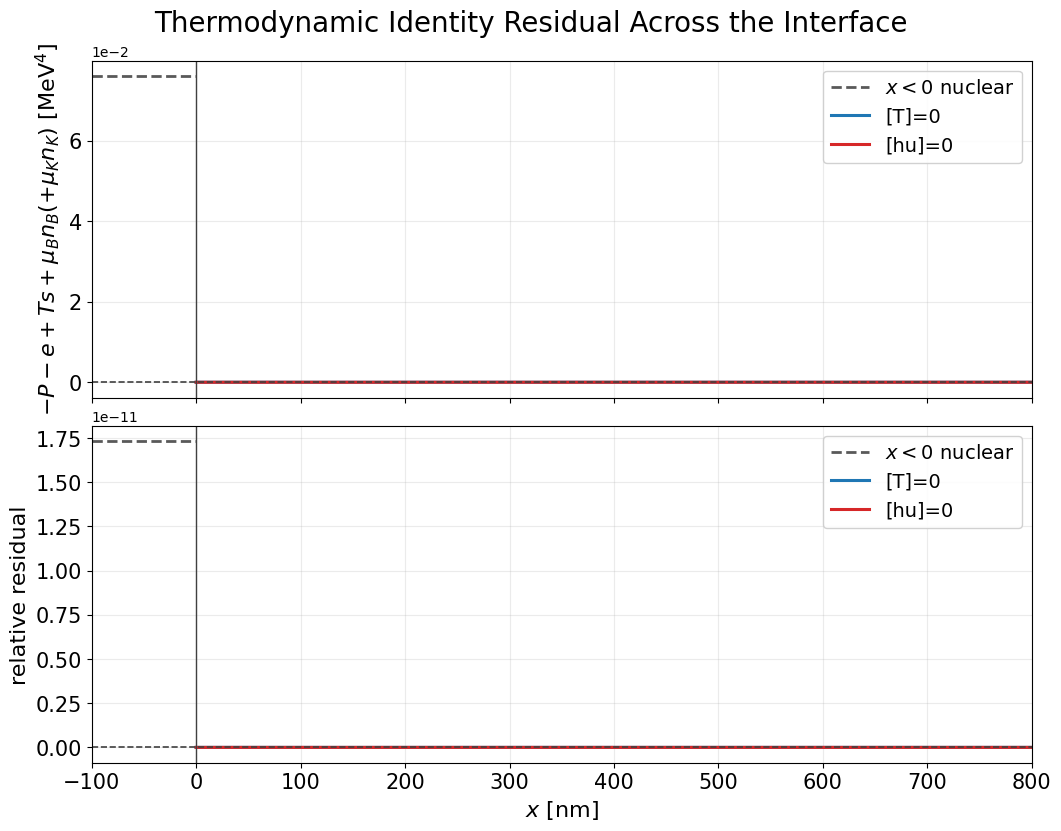

In [3]:
# VISUALIZE_ADIABATIC_THERMO_IDENTITY_RESIDUAL
# Check -P - e + T*s + muB*nB + muK*nK along the reconstructed adiabatic profiles.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.SQMsolver import PQM, edensQM
from RMFsolver.phase_velocity import PNM_n, edensNM_n, sNM_n, _solve_scalar_root, nB_NM

required_identity_names = [
    'res_adiabatic_legacy_trial',
    'res_adiabatic_jump_trial',
    'B14_compare_trial',
    'ms_compare_trial',
    'T_compare_trial',
    'nB_N_compare_trial',
]
missing_identity_names = [name for name in required_identity_names if name not in globals()]
if missing_identity_names:
    raise RuntimeError(
        'Run the ADIABATIC_LEGACY_JUMP_PROFILE_CALC cell first. Missing names: '
        + ', '.join(missing_identity_names)
    )

identity_plot_modes = [
    ('[T]=0', res_adiabatic_legacy_trial, 'C0'),
    ('[hu]=0', res_adiabatic_jump_trial, 'C3'),
]


def _thermo_identity_profile(result):
    x_nm = np.asarray(result['x'], dtype=float) * const.MeV_fm / 1.0e6
    a_values = np.asarray(result['a'], dtype=float)
    muB_values = np.asarray(result['muB'], dtype=float)
    muK_values = np.asarray(result['muK'], dtype=float)
    T_values = np.asarray(result['T_profile'], dtype=float)
    s_values = np.asarray(result['s_profile'], dtype=float)
    nB_values = np.asarray(result['nB'], dtype=float)
    nB_Q = float(result['nB_Q'])

    # Requested diagnostic convention: nK = a * nB_Q.
    nK_values = a_values * nB_Q

    P_values = np.empty_like(muB_values)
    e_values = np.empty_like(muB_values)
    for i, (muB_value, muK_value, T_value) in enumerate(zip(muB_values, muK_values, T_values)):
        P_values[i] = PQM(
            float(muB_value),
            float(muK_value),
            B14_compare_trial,
            float(T_value),
            ms=ms_compare_trial,
        )
        e_values[i] = edensQM(
            float(muB_value),
            float(muK_value),
            B14_compare_trial,
            float(T_value),
            ms=ms_compare_trial,
            include_em=False,
        )

    residual = -P_values - e_values + T_values * s_values + muB_values * nB_values + muK_values * nK_values
    scale = np.maximum.reduce([
        np.abs(P_values),
        np.abs(e_values),
        np.abs(T_values * s_values),
        np.abs(muB_values * nB_values),
        np.abs(muK_values * nK_values),
        np.ones_like(residual),
    ])
    return {
        'x_nm': x_nm,
        'residual': residual,
        'relative_residual': residual / scale,
        'nK': nK_values,
    }


def _nuclear_identity_branch(x_left_nm):
    P_N = float(PNM_n(nB_N_compare_trial, T_compare_trial))
    e_N = float(edensNM_n(nB_N_compare_trial, T_compare_trial))
    s_N = float(sNM_n(nB_N_compare_trial, T_compare_trial))
    muB_N = float(
        _solve_scalar_root(
            lambda muB: nB_NM(muB, T_compare_trial) - nB_N_compare_trial,
            1050.0,
        )
    )
    residual_value = float(-P_N - e_N + T_compare_trial * s_N + muB_N * nB_N_compare_trial)
    scale_value = max(abs(P_N), abs(e_N), abs(T_compare_trial * s_N), abs(muB_N * nB_N_compare_trial), 1.0)
    residual = np.full_like(x_left_nm, residual_value, dtype=float)
    relative_residual = np.full_like(x_left_nm, residual_value / scale_value, dtype=float)
    return {
        'x_nm': x_left_nm,
        'residual': residual,
        'relative_residual': relative_residual,
        'muB_N': muB_N,
    }

TitleFont = 20
LabelFont = 16
TickFont = 15
LegendFont = 14

fig, axes = plt.subplots(2, 1, figsize=(10.5, 8.2), sharex=True, constrained_layout=True)
identity_profiles = {}
x_left_nm_identity = np.linspace(-100.0, 0.0, 120)
nuclear_identity = _nuclear_identity_branch(x_left_nm_identity)

axes[0].plot(
    nuclear_identity['x_nm'], nuclear_identity['residual'],
    lw=2.0, ls='--', color='0.35', label=r'$x<0$ nuclear'
)
axes[1].plot(
    nuclear_identity['x_nm'], nuclear_identity['relative_residual'],
    lw=2.0, ls='--', color='0.35', label=r'$x<0$ nuclear'
)

print('Thermodynamic identity check using nK = a*nB_Q on x>0 and -P-e+Ts+muB*nB on x<0:')
print(
    f"  x<0 nuclear: residual={nuclear_identity['residual'][0]:.6e}, "
    f"relative={nuclear_identity['relative_residual'][0]:.6e}, "
    f"muB_N={nuclear_identity['muB_N']:.6g} MeV"
)
for label, result, color in identity_plot_modes:
    prof = _thermo_identity_profile(result)
    identity_profiles[label] = prof
    axes[0].plot(prof['x_nm'], prof['residual'], lw=2.2, color=color, label=label)
    axes[1].plot(prof['x_nm'], prof['relative_residual'], lw=2.2, color=color, label=label)
    print(
        f"  {label}: max|residual|={np.nanmax(np.abs(prof['residual'])):.6e}, "
        f"max|relative|={np.nanmax(np.abs(prof['relative_residual'])):.6e}"
    )

axes[0].axhline(0.0, color='0.25', lw=1.2, ls='--')
axes[1].axhline(0.0, color='0.25', lw=1.2, ls='--')
axes[0].set_ylabel(r'$-P-e+Ts+\mu_B n_B(+\mu_K n_K)$ [MeV$^4$]', fontsize=LabelFont)
axes[1].set_ylabel('relative residual', fontsize=LabelFont)
axes[1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[0].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

for ax in axes:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-100, 800)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

fig.suptitle('Thermodynamic Identity Residual Across the Interface', fontsize=TitleFont)
plt.savefig('adiabatic_thermo_identity_residual.pdf', bbox_inches='tight', dpi=300)
plt.show()


Nuclear-side entropy-method consistency check:
  T_N = 10 MeV
  nB_N = 3.68808153e+06 MeV^3
  muB_N from RMF solution = 1190.639 MeV
  P_N = 6.10829152e+08 MeV^4
  e_direct = 3.79013966e+09 MeV^4
  s_integral = 1.54156719e+06 MeV^3
  s_thermal = 9.79503255e+05 MeV^3
  s_integral - s_thermal = 5.62063938e+05 MeV^3
  e_thermo_integral = 3.79576030e+09 MeV^4
  e_thermo_thermal = 3.79013966e+09 MeV^4
  residual using integral entropy = 5.62063946e+06 MeV^4
  residual using thermal entropy = 8.34045410e-02 MeV^4
  relative residual using integral entropy = 1.48296368e-03
  relative residual using thermal entropy = 2.20056643e-11


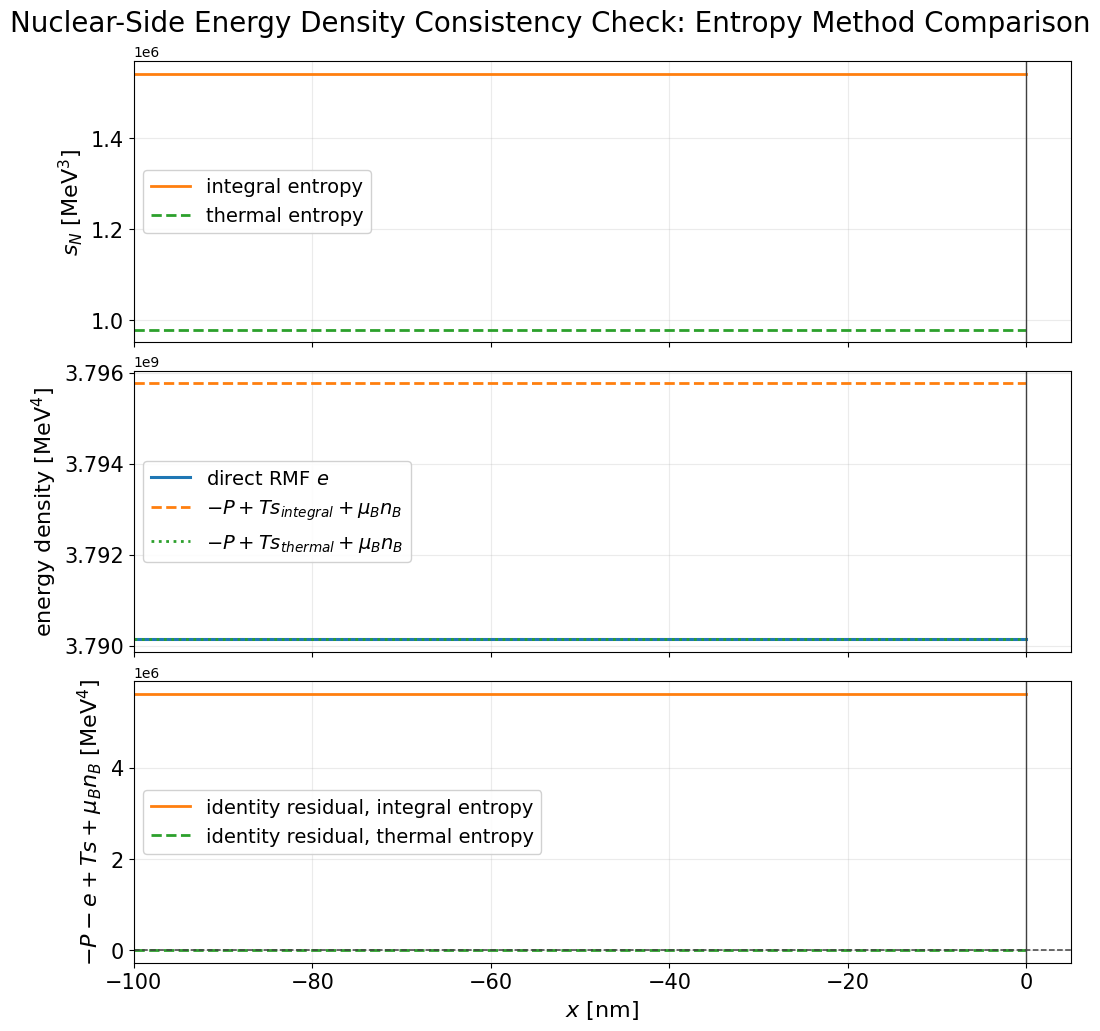

In [4]:
# VISUALIZE_NUCLEAR_DIRECT_VS_THERMO_ENERGY_DENSITY
# Compare direct RMF energy density with e_thermo = -P + T*s + muB*nB using both RMF entropy methods.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.Solver import RMFsolvePNM, pressure_RMF, edens_RMF, entropy_RMF

required_nuclear_energy_names = [
    'T_compare_trial',
    'nB_N_compare_trial',
    'param_compare_trial',
    'NM_type_compare_trial',
]
missing_nuclear_energy_names = [name for name in required_nuclear_energy_names if name not in globals()]
if missing_nuclear_energy_names:
    raise RuntimeError(
        'Run the ADIABATIC_LEGACY_JUMP_PROFILE_CALC cell first. Missing names: '
        + ', '.join(missing_nuclear_energy_names)
    )
if NM_type_compare_trial != 'PNM':
    raise RuntimeError('This diagnostic cell currently uses RMFsolvePNM and expects NM_type_compare_trial == "PNM".')

x_left_nm_energy = np.linspace(-100.0, 0.0, 120)

rmf_sol_N = RMFsolvePNM(
    nB_N_compare_trial,
    T_compare_trial,
    param_compare_trial,
    sigma_init=30,
    w0_init=20,
    r03_init=-3,
    mub_init=990,
    verb=False,
)
muB_N_from_solution = float(rmf_sol_N[0][3])

P_N_direct = float(
    pressure_RMF(
        rmf_sol_N,
        add_photons=False,
        renorm=False,
        electrons=False,
        neutrinos=False,
    )
)
_, e_N_direct, _ = edens_RMF(
    rmf_sol_N,
    add_photons=False,
    renorm=False,
    electrons=False,
    neutrinos=False,
    use_entropy=False,
)
e_N_direct = float(e_N_direct)

s_N_integral = float(
    entropy_RMF(
        rmf_sol_N,
        add_photons=False,
        electrons=False,
        neutrinos=False,
        use_thermal=False,
    )
)
s_N_thermal = float(
    entropy_RMF(
        rmf_sol_N,
        add_photons=False,
        electrons=False,
        neutrinos=False,
        use_thermal=True,
    )
)

e_N_thermo_integral = float(-P_N_direct + T_compare_trial * s_N_integral + muB_N_from_solution * nB_N_compare_trial)
e_N_thermo_thermal = float(-P_N_direct + T_compare_trial * s_N_thermal + muB_N_from_solution * nB_N_compare_trial)

identity_residual_integral = float(-P_N_direct - e_N_direct + T_compare_trial * s_N_integral + muB_N_from_solution * nB_N_compare_trial)
identity_residual_thermal = float(-P_N_direct - e_N_direct + T_compare_trial * s_N_thermal + muB_N_from_solution * nB_N_compare_trial)
relative_residual_integral = float(identity_residual_integral / max(abs(e_N_direct), 1.0))
relative_residual_thermal = float(identity_residual_thermal / max(abs(e_N_direct), 1.0))

energy_profiles = {
    'direct': np.full_like(x_left_nm_energy, e_N_direct, dtype=float),
    'thermo_integral': np.full_like(x_left_nm_energy, e_N_thermo_integral, dtype=float),
    'thermo_thermal': np.full_like(x_left_nm_energy, e_N_thermo_thermal, dtype=float),
    'residual_integral': np.full_like(x_left_nm_energy, identity_residual_integral, dtype=float),
    'residual_thermal': np.full_like(x_left_nm_energy, identity_residual_thermal, dtype=float),
    's_integral': np.full_like(x_left_nm_energy, s_N_integral, dtype=float),
    's_thermal': np.full_like(x_left_nm_energy, s_N_thermal, dtype=float),
}

TitleFont = 20
LabelFont = 16
TickFont = 15
LegendFont = 14

fig, axes = plt.subplots(3, 1, figsize=(10.5, 10.2), sharex=True, constrained_layout=True)

axes[0].plot(x_left_nm_energy, energy_profiles['s_integral'], lw=2.0, color='C1', label='integral entropy')
axes[0].plot(x_left_nm_energy, energy_profiles['s_thermal'], lw=2.0, ls='--', color='C2', label='thermal entropy')

axes[1].plot(x_left_nm_energy, energy_profiles['direct'], lw=2.2, color='C0', label=r'direct RMF $e$')
axes[1].plot(x_left_nm_energy, energy_profiles['thermo_integral'], lw=2.0, ls='--', color='C1', label=r'$-P+T s_{integral}+\mu_B n_B$')
axes[1].plot(x_left_nm_energy, energy_profiles['thermo_thermal'], lw=2.0, ls=':', color='C2', label=r'$-P+T s_{thermal}+\mu_B n_B$')

axes[2].plot(x_left_nm_energy, energy_profiles['residual_integral'], lw=2.0, color='C1', label='identity residual, integral entropy')
axes[2].plot(x_left_nm_energy, energy_profiles['residual_thermal'], lw=2.0, ls='--', color='C2', label='identity residual, thermal entropy')
axes[2].axhline(0.0, color='0.25', lw=1.1, ls='--')

axes[0].set_ylabel(r'$s_N$ [MeV$^3$]', fontsize=LabelFont)
axes[1].set_ylabel(r'energy density [MeV$^4$]', fontsize=LabelFont)
axes[2].set_ylabel(r'$-P-e+Ts+\mu_B n_B$ [MeV$^4$]', fontsize=LabelFont)
axes[2].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
for ax in axes:
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

for ax in axes:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(float(np.min(x_left_nm_energy)), 5.0)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

fig.suptitle('Nuclear-Side Energy Density Consistency Check: Entropy Method Comparison', fontsize=TitleFont)

print('Nuclear-side entropy-method consistency check:')
print(f'  T_N = {T_compare_trial:.8g} MeV')
print(f'  nB_N = {nB_N_compare_trial:.8e} MeV^3')
print(f'  muB_N from RMF solution = {muB_N_from_solution:.8g} MeV')
print(f'  P_N = {P_N_direct:.8e} MeV^4')
print(f'  e_direct = {e_N_direct:.8e} MeV^4')
print(f'  s_integral = {s_N_integral:.8e} MeV^3')
print(f'  s_thermal = {s_N_thermal:.8e} MeV^3')
print(f'  s_integral - s_thermal = {s_N_integral - s_N_thermal:.8e} MeV^3')
print(f'  e_thermo_integral = {e_N_thermo_integral:.8e} MeV^4')
print(f'  e_thermo_thermal = {e_N_thermo_thermal:.8e} MeV^4')
print(f'  residual using integral entropy = {identity_residual_integral:.8e} MeV^4')
print(f'  residual using thermal entropy = {identity_residual_thermal:.8e} MeV^4')
print(f'  relative residual using integral entropy = {relative_residual_integral:.8e}')
print(f'  relative residual using thermal entropy = {relative_residual_thermal:.8e}')

plt.savefig('nuclear_entropy_method_energy_consistency.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [81]:
s_left[-1]/ result['s_profile'][0]

np.float64(0.908338351671844)

In [21]:
from RMFsolver.SQMsolver import PQM
from RMFsolver.phase_velocity import PNM, nB_NM
from scipy.optimize import fsolve

n0 = 0.16 * const.MeV_fm**3

muB_crit = fsolve(lambda x: PNM(x, 10) - PQM(x, 0, 160, 10), 1010)[0]
nB_NM(muB_crit, 10)/n0, muB_crit

(0.0049558736207315724, np.float64(909.1360963445004))

In [24]:
(max(prof['h']) - min(prof['h']))/np.mean(prof['h']), (max(prof['u_ms']) - min(prof['u_ms']))/np.mean(prof['u_ms'])

(np.float64(6.216784243872407e-14), np.float64(2.3362866231209422e-11))

## `aQstar` sample calculation cell

This cell samples several `aQstar` values using the temperature-continuity branch, `interface_temperature_mode='T_const'`, and records the upstream velocity `u_N` returned by the adiabatic solver. It also stores the corresponding solver-reconstructed `a_N` values for the dashed reference in the plot cell.


In [33]:
# A_QSTAR_UN_VELOCITY_SAMPLE_CALC
# Sample u_N as a function of aQstar in the T_const branch.

import numpy as np

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import solve_front_adiabatic

if 'n0' not in globals():
    n0 = 0.16 * const.MeV_fm**3

T_aQstar_scan = globals().get('T_compare_trial', 10.0)
nB_N_aQstar_scan = globals().get('nB_N_compare_trial', 3.0 * n0)
B14_aQstar_scan = globals().get('B14_compare_trial', 180.0)
ms_aQstar_scan = globals().get('ms_compare_trial', 0.0)
NM_type_aQstar_scan = globals().get('NM_type_compare_trial', 'PNM')
param_aQstar_scan = globals().get('param_compare_trial', para.paraQMCRMF3)
TQ_guess_aQstar_scan = globals().get('TQ_guess_compare_trial', 80.0)

# These defaults are selected to converge for the current T_compare_trial/TQ_guess_compare_trial.
# Edit this array directly if you want to probe a wider aQstar range.
aQstar_samples = np.array([0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70], dtype=float)

common_aQstar_scan_kwargs = dict(
    T=T_aQstar_scan,
    nB_N=nB_N_aQstar_scan,
    B_one_forth=B14_aQstar_scan,
    ms=ms_aQstar_scan,
    param=param_aQstar_scan,
    NM_type=NM_type_aQstar_scan,
    tail_eps=1.0e-6,
    n_mesh=40,
    tol_bvp=1.0e-5,
    max_nodes=1200,
    jB_guess=None,
    TQ_guess=TQ_guess_aQstar_scan,
    jB_bounds=(1.0e-5, 5.0),
    interface_temperature_mode='T_const',
    return_profile=False,
    verb=False,
)

aQstar_scan_results = []
for aQstar_value in aQstar_samples:
    result = solve_front_adiabatic(
        **common_aQstar_scan_kwargs,
        aQstar=float(aQstar_value),
    )
    row = {
        'aQstar': float(aQstar_value),
        'success': bool(result.get('success')),
        'message': result.get('message', ''),
        'jB': float(result.get('jB', np.nan)),
        'u_N': float(result.get('u_N', np.nan)),
        'u_N_m_per_s': float(result.get('u_N', np.nan)) * const.m_per_sec,
        'a_N': float(result.get('a_N', np.nan)),
        'T_Q': float(result.get('T_Q', np.nan)),
        'T_Qstar': float(result.get('T_Qstar', np.nan)),
        'tail_residual_norm': float(result.get('tail_residual_norm', np.nan)),
        'entropy_tail_residual_norm': float(result.get('entropy_tail_residual_norm', np.nan)),
    }
    aQstar_scan_results.append(row)
    print(
        f"aQstar={row['aQstar']:.3f}: "
        f"success={row['success']}, "
        f"u_N={row['u_N_m_per_s']:.6g} m/s, "
        f"a_N={row['a_N']:.6g}, "
        f"T_Q={row['T_Q']:.6g} MeV"
    )

failed_aQstar_samples = [row for row in aQstar_scan_results if not row['success']]
if failed_aQstar_samples:
    failed_summary = '; '.join(
        f"aQstar={row['aQstar']:.3f}: {row['message']}"
        for row in failed_aQstar_samples
    )
    raise RuntimeError(f'Some aQstar scan points failed: {failed_summary}')


aQstar=0.100: success=True, u_N=15.0437 m/s, a_N=0.642263, T_Q=5.8534 MeV
aQstar=0.200: success=True, u_N=38.267 m/s, a_N=0.644405, T_Q=11.5864 MeV
aQstar=0.300: success=True, u_N=67.6545 m/s, a_N=0.647987, T_Q=17.365 MeV
aQstar=0.400: success=True, u_N=104.074 m/s, a_N=0.653025, T_Q=23.1778 MeV
aQstar=0.500: success=True, u_N=150.003 m/s, a_N=0.659546, T_Q=29.0315 MeV
aQstar=0.600: success=False, u_N=nan m/s, a_N=nan, T_Q=nan MeV
aQstar=0.700: success=False, u_N=nan m/s, a_N=nan, T_Q=nan MeV


RuntimeError: Some aQstar scan points failed: aQstar=0.600: The maximum number of mesh nodes is exceeded.; last failure: Entropy-enabled local quark-state solve failed: single-guess entropy-enabled quark-state solve failed: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.; continuation seed at aQstar=0.01 failed: BVP final state construction failed: Local microphysics returned non-physical coefficients: Quark diffusion coefficient denominator is non-physical; aQstar=0.700: BVP final state construction failed: (34, 'Result too large'); continuation seed at aQstar=0.01 failed: BVP final state construction failed: Local microphysics returned non-physical coefficients: Quark diffusion coefficient denominator is non-physical

## `aQstar` sample visualization cell

This cell plots the sampled upstream velocity `u_N` against `aQstar`. The dashed reference shows the corresponding `a_N` values on the right-hand axis.


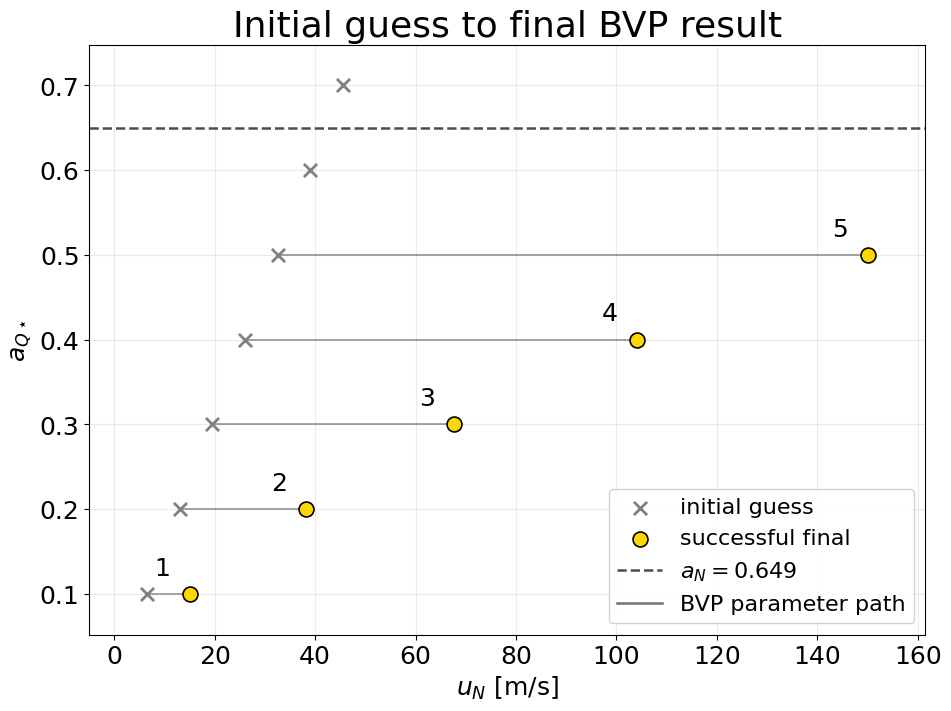

In [34]:
# VISUALIZE_A_QSTAR_UN_VELOCITY_SAMPLE
# Plot initial u_N guesses and final BVP u_N values against aQstar.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import RMFsolver.constants as const

if 'aQstar_scan_results' not in globals():
    raise RuntimeError('Run the A_QSTAR_UN_VELOCITY_SAMPLE_CALC cell first.')

scan_aQstar = np.array([row['aQstar'] for row in aQstar_scan_results], dtype=float)
scan_uN_ms = np.array([row['u_N_m_per_s'] for row in aQstar_scan_results], dtype=float)
scan_aN = np.array([row['a_N'] for row in aQstar_scan_results], dtype=float)
scan_success = np.array([bool(row['success']) for row in aQstar_scan_results], dtype=bool)

jB_guess_setting = common_aQstar_scan_kwargs.get('jB_guess', None)
if jB_guess_setting is None:
    scan_initial_jB = np.array(
        [max(1.0e-12, 1.0e-8 * nB_N_aQstar_scan, 0.8 * abs(a_value)) for a_value in scan_aQstar],
        dtype=float,
    )
else:
    scan_initial_jB = np.full_like(scan_aQstar, float(jB_guess_setting), dtype=float)
scan_initial_uN_ms = scan_initial_jB / nB_N_aQstar_scan * const.m_per_sec

finite_final = np.isfinite(scan_uN_ms) & np.isfinite(scan_aQstar)
success_final = scan_success & finite_final
failed_finite_final = (~scan_success) & finite_final
aN_reference = float(np.nanmean(scan_aN))

TitleFont = 26
LabelFont = 18
TickFont = 18
LegendFont = 16

fig, ax = plt.subplots(figsize=(9.4, 7.0), constrained_layout=True)

for a_value, x0, x1, ok in zip(scan_aQstar, scan_initial_uN_ms, scan_uN_ms, scan_success):
    if np.isfinite(x0) and np.isfinite(x1):
        ax.plot([x0, x1], [a_value, a_value], color='0.45', lw=1.4, alpha=0.65)

ax.scatter(
    scan_initial_uN_ms,
    scan_aQstar,
    marker='x',
    s=90,
    lw=2.0,
    color='0.50',
    label='initial guess',
    zorder=3,
)
ax.scatter(
    scan_uN_ms[success_final],
    scan_aQstar[success_final],
    marker='o',
    s=115,
    facecolor='gold',
    edgecolor='black',
    linewidth=1.2,
    label='successful final',
    zorder=4,
)
if np.any(failed_finite_final):
    ax.scatter(
        scan_uN_ms[failed_finite_final],
        scan_aQstar[failed_finite_final],
        marker='o',
        s=115,
        facecolor='none',
        edgecolor='red',
        linewidth=1.2,
        label='failed finite final',
        zorder=4,
    )

ax.axhline(aN_reference, color='0.30', lw=1.8, ls='--', label=rf'$a_N={aN_reference:.3f}$')

for idx, (a_value, x_value, ok) in enumerate(zip(scan_aQstar, scan_uN_ms, scan_success), start=1):
    if not np.isfinite(x_value):
        continue
    ax.annotate(
        str(idx),
        xy=(x_value, a_value),
        xytext=(-14, 10 if ok else 8),
        textcoords='offset points',
        ha='right',
        va='bottom',
        fontsize=18,
        color='black' if ok else 'red',
    )

path_handle = Line2D([0], [0], color='0.45', lw=1.8, label='BVP parameter path')
handles, labels = ax.get_legend_handles_labels()
insert_at = min(3, len(handles))
handles.insert(insert_at, path_handle)
labels.insert(insert_at, path_handle.get_label())
ax.legend(handles, labels, fontsize=LegendFont, loc='lower right', framealpha=0.88)

all_x = np.concatenate([scan_initial_uN_ms[np.isfinite(scan_initial_uN_ms)], scan_uN_ms[np.isfinite(scan_uN_ms)]])
if all_x.size:
    x_pad = 0.08 * max(float(np.nanmax(all_x) - np.nanmin(all_x)), 1.0)
    ax.set_xlim(float(np.nanmin(all_x) - x_pad), float(np.nanmax(all_x) + x_pad))
y_values = np.concatenate([scan_aQstar[np.isfinite(scan_aQstar)], np.array([aN_reference])])
y_pad = 0.08 * max(float(np.nanmax(y_values) - np.nanmin(y_values)), 0.1)
ax.set_ylim(float(np.nanmin(y_values) - y_pad), float(np.nanmax(y_values) + y_pad))

ax.set_title('Initial guess to final BVP result', fontsize=TitleFont)
ax.set_xlabel(r'$u_N$ [m/s]', fontsize=LabelFont)
ax.set_ylabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax.grid(alpha=0.25)
ax.tick_params(labelsize=TickFont)

plt.savefig('adiabatic_aQstar_uN_samples.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [8]:
# A_QSTAR_UPPER_BOUND_TWO_MODE_CALC
# Adaptive profile-seeded continuation scan for T_const and hu_const.

import numpy as np
import pandas as pd

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import (
    solve_front_adiabatic,
    _solve_front_adiabatic_once,
    PNM_n,
    edensNM_n,
    _solve_muB_Q_at_muK0_for_given_Pi_ms,
    _solve_interface_Qstar_from_aQstar_and_Pi,
    _solve_interface_Qstar_enthalpy_jump,
    _quark_thermo_state,
)

# Self-contained inputs for this scan. Do not inherit values from earlier notebook cells.
n0_upper_bound_scan = 0.16 * const.MeV_fm**3
T_upper_bound_scan = 10.0
nB_N_upper_bound_scan = 3.0 * n0_upper_bound_scan
B14_upper_bound_scan = 180.0
ms_upper_bound_scan = 0.0
NM_type_upper_bound_scan = 'PNM'
param_upper_bound_scan = para.paraQMCRMF3

# Tune these knobs for the upper-bound search.
aQstar_upper_bound_modes = ('T_const', 'hu_const')
aQstar_upper_bound_start = 0.30
aQstar_upper_bound_max = 1.20
aQstar_upper_bound_da_initial = 0.01
aQstar_upper_bound_da_min = 1.0e-4
aQstar_upper_bound_max_attempts_per_mode = 120

# Separate tunable BVP guesses and controls. These are also self-contained.
jB_guess_upper_bound_scan = None
TQ_guess_upper_bound_scan = 80.0
jB_bounds_upper_bound_scan = (1.0e-5, 5.0)
tail_eps_upper_bound_scan = 1.0e-6
n_mesh_upper_bound_scan = 40
tol_upper_bound_scan = 1.0e-5
max_nodes_upper_bound_scan = 2500

upper_bound_common_kwargs = dict(
    T=T_upper_bound_scan,
    nB_N=nB_N_upper_bound_scan,
    B_one_forth=B14_upper_bound_scan,
    ms=ms_upper_bound_scan,
    param=param_upper_bound_scan,
    NM_type=NM_type_upper_bound_scan,
    tail_eps=tail_eps_upper_bound_scan,
    n_mesh=n_mesh_upper_bound_scan,
    tol_bvp=tol_upper_bound_scan,
    max_nodes=max_nodes_upper_bound_scan,
    jB_bounds=jB_bounds_upper_bound_scan,
    verb=False,
)


def _as_float(value):
    try:
        return float(value)
    except Exception:
        return np.nan


def _clip_jB_guess(jB_value):
    jB_value = _as_float(jB_value)
    if not np.isfinite(jB_value) or jB_value <= 0.0:
        return np.nan
    if jB_bounds_upper_bound_scan is None:
        return jB_value
    lower, upper = map(float, jB_bounds_upper_bound_scan)
    return float(np.clip(jB_value, lower * (1.0 + 1.0e-6), upper * (1.0 - 1.0e-6)))


def _trial_seed_from_history(history, target_a):
    if not history:
        return _clip_jB_guess(jB_guess_upper_bound_scan), _as_float(TQ_guess_upper_bound_scan)
    last = history[-1]
    jB_trial = _as_float(last.get('jB'))
    TQ_trial = _as_float(last.get('T_Q'))
    if len(history) >= 2:
        prev = history[-2]
        da_prev = _as_float(last.get('aQstar')) - _as_float(prev.get('aQstar'))
        da_next = float(target_a) - _as_float(last.get('aQstar'))
        if np.isfinite(da_prev) and abs(da_prev) > 0.0 and np.isfinite(da_next):
            jB_trial = jB_trial + (_as_float(last.get('jB')) - _as_float(prev.get('jB'))) / da_prev * da_next
            TQ_trial = TQ_trial + (_as_float(last.get('T_Q')) - _as_float(prev.get('T_Q'))) / da_prev * da_next
    return _clip_jB_guess(jB_trial), max(_as_float(TQ_trial), 1.0e-8)


def _algebraic_qstar_check(mode, aQstar_value, jB_trial, TQ_trial):
    jB_trial = _clip_jB_guess(jB_trial)
    TQ_trial = _as_float(TQ_trial)
    if (not np.isfinite(jB_trial)) or jB_trial <= 0.0 or (not np.isfinite(TQ_trial)) or TQ_trial <= 0.0:
        return {
            'algebraic_ok': False,
            'failure_label': 'unknown/inconclusive',
            'algebraic_message': 'No finite positive trial jB/T_Q was available for the algebraic check.',
            'algebraic_a_N': np.nan,
            'algebraic_T_Qstar': np.nan,
            'algebraic_h_over_nB_jump_residual': np.nan,
        }

    try:
        P_N = float(PNM_n(nB_N_upper_bound_scan, T_upper_bound_scan, param=param_upper_bound_scan, NM_type=NM_type_upper_bound_scan))
        e_N = float(edensNM_n(nB_N_upper_bound_scan, T_upper_bound_scan, param=param_upper_bound_scan))
        h_N = P_N + e_N
        h_over_nB_N = h_N / nB_N_upper_bound_scan
        u_N = jB_trial / nB_N_upper_bound_scan
        Pi = h_N * u_N * u_N + P_N

        muB_Q = _solve_muB_Q_at_muK0_for_given_Pi_ms(
            Pi,
            jB_trial,
            B14_upper_bound_scan,
            TQ_trial,
            ms=ms_upper_bound_scan,
            initial_guess=1200.0,
        )
        thermo_Q = _quark_thermo_state(muB_Q, 0.0, B14_upper_bound_scan, TQ_trial, jB_trial, ms=ms_upper_bound_scan)
        nB_Q = float(thermo_Q['nB'])
        nK_Q = 0.0 if abs(ms_upper_bound_scan) <= 1.0e-12 else float(thermo_Q['nK'])
        muK_seed = max(20.0, 250.0 * abs(float(aQstar_value)))

        if mode == 'hu_const':
            thermo_Qstar = _solve_interface_Qstar_enthalpy_jump(
                aQstar_value,
                Pi,
                jB_trial,
                nB_Q,
                nK_Q,
                B14_upper_bound_scan,
                h_over_nB_N,
                T_upper_bound_scan,
                TQ_trial,
                ms=ms_upper_bound_scan,
                initial_guess=(muB_Q, muK_seed, TQ_trial),
            )
        else:
            muB_Qstar, muK_Qstar = _solve_interface_Qstar_from_aQstar_and_Pi(
                aQstar_value,
                Pi,
                jB_trial,
                nB_Q,
                nK_Q,
                B14_upper_bound_scan,
                T_upper_bound_scan,
                ms=ms_upper_bound_scan,
                initial_guess=np.array([muB_Q, muK_seed], dtype=float),
            )
            thermo_Qstar = _quark_thermo_state(
                muB_Qstar,
                muK_Qstar,
                B14_upper_bound_scan,
                T_upper_bound_scan,
                jB_trial,
                ms=ms_upper_bound_scan,
            )

        h_over_nB_Qstar = float(thermo_Qstar['h'] / thermo_Qstar['nB'])
        return {
            'algebraic_ok': True,
            'failure_label': 'BVP/local closure failure',
            'algebraic_message': 'Endpoint and Qstar algebraic states exist at the extrapolated trial point.',
            'algebraic_a_N': float((nB_N_upper_bound_scan - nK_Q) / nB_Q),
            'algebraic_T_Qstar': float(thermo_Qstar['T']),
            'algebraic_h_over_nB_jump_residual': float(h_over_nB_Qstar - h_over_nB_N),
        }
    except Exception as exc:
        return {
            'algebraic_ok': False,
            'failure_label': 'algebraic thermodynamic failure',
            'algebraic_message': str(exc),
            'algebraic_a_N': np.nan,
            'algebraic_T_Qstar': np.nan,
            'algebraic_h_over_nB_jump_residual': np.nan,
        }


def _result_row(mode, aQstar_value, result, attempt_kind, jB_trial=np.nan, TQ_trial=np.nan, algebraic=None):
    algebraic = algebraic or {}
    u_N = _as_float(result.get('u_N', np.nan))
    jB_value = _as_float(result.get('jB', np.nan))
    TQ_value = _as_float(result.get('T_Q', np.nan))
    a_N = _as_float(result.get('a_N', np.nan))
    u_N_trial = _as_float(jB_trial) / nB_N_upper_bound_scan if np.isfinite(_as_float(jB_trial)) else np.nan
    return {
        'mode': mode,
        'aQstar': float(aQstar_value),
        'success': bool(result.get('success')),
        'attempt_kind': attempt_kind,
        'jB': jB_value,
        'u_N': u_N,
        'u_N_m_s': u_N * const.m_per_sec if np.isfinite(u_N) else np.nan,
        'T_Q': TQ_value,
        'T_Qstar': _as_float(result.get('T_Qstar', np.nan)),
        'a_N': a_N,
        'a_N_minus_aQstar': a_N - float(aQstar_value) if np.isfinite(a_N) else np.nan,
        'h_over_nB_jump_residual': _as_float(result.get('h_over_nB_jump_residual', np.nan)),
        'bvp_nodes': _as_float(result.get('bvp_nodes', np.nan)),
        'local_state_failures': _as_float(result.get('local_state_failures', np.nan)),
        'global_state_failures': _as_float(result.get('global_state_failures', np.nan)),
        'message': str(result.get('message', '')),
        'jB_trial': _as_float(jB_trial),
        'T_Q_trial': _as_float(TQ_trial),
        'u_N_trial_m_s': u_N_trial * const.m_per_sec if np.isfinite(u_N_trial) else np.nan,
        'u_N_plot_m_s': u_N * const.m_per_sec if np.isfinite(u_N) else (u_N_trial * const.m_per_sec if np.isfinite(u_N_trial) else np.nan),
        'algebraic_ok': bool(algebraic.get('algebraic_ok', False)) if not bool(result.get('success')) else True,
        'failure_label': 'success' if bool(result.get('success')) else algebraic.get('failure_label', 'unknown/inconclusive'),
        'algebraic_message': algebraic.get('algebraic_message', ''),
        'algebraic_a_N': _as_float(algebraic.get('algebraic_a_N', np.nan)),
        'algebraic_T_Qstar': _as_float(algebraic.get('algebraic_T_Qstar', np.nan)),
        'algebraic_h_over_nB_jump_residual': _as_float(algebraic.get('algebraic_h_over_nB_jump_residual', np.nan)),
    }


aQstar_upper_bound_attempts = []
aQstar_upper_bound_success_profiles = {}

for mode in aQstar_upper_bound_modes:
    print(f'\n=== {mode}: adaptive aQstar continuation ===')
    seed = solve_front_adiabatic(
        **upper_bound_common_kwargs,
        aQstar=aQstar_upper_bound_start,
        jB_guess=jB_guess_upper_bound_scan,
        TQ_guess=TQ_guess_upper_bound_scan,
        interface_temperature_mode=mode,
        return_profile=True,
    )
    seed_row = _result_row(mode, aQstar_upper_bound_start, seed, 'seed')
    aQstar_upper_bound_attempts.append(seed_row)
    print(
        f"seed aQstar={aQstar_upper_bound_start:.5f}: success={seed_row['success']}, "
        f"u_N={seed_row['u_N_m_s']:.6g} m/s, T_Q={seed_row['T_Q']:.6g}, "
        f"T_Qstar={seed_row['T_Qstar']:.6g}"
    )
    if not seed_row['success']:
        print(f"  seed failed: {seed_row['message'][:220]}")
        continue

    current = seed
    current_a = float(aQstar_upper_bound_start)
    da = float(aQstar_upper_bound_da_initial)
    history = [seed_row]
    attempts = 0

    while current_a < aQstar_upper_bound_max - 1.0e-12 and attempts < aQstar_upper_bound_max_attempts_per_mode:
        attempts += 1
        target_a = float(min(aQstar_upper_bound_max, current_a + da))
        jB_trial, TQ_trial = _trial_seed_from_history(history, target_a)
        trial = _solve_front_adiabatic_once(
            **upper_bound_common_kwargs,
            aQstar=target_a,
            jB_guess=current.get('jB'),
            TQ_guess=current.get('T_Q'),
            interface_temperature_mode=mode,
            return_profile=True,
            profile_guess=current,
            seed_profile=True,
        )

        if bool(trial.get('success')):
            row = _result_row(mode, target_a, trial, 'continuation_success')
            aQstar_upper_bound_attempts.append(row)
            history.append(row)
            current = trial
            current_a = target_a
            da = min(float(aQstar_upper_bound_da_initial), max(da, float(aQstar_upper_bound_da_min)))
            print(
                f"aQstar={target_a:.5f}: success, u_N={row['u_N_m_s']:.6g} m/s, "
                f"T_Q={row['T_Q']:.6g}, T_Qstar={row['T_Qstar']:.6g}, a_N-aQstar={row['a_N_minus_aQstar']:.6g}"
            )
        else:
            algebraic = _algebraic_qstar_check(mode, target_a, jB_trial, TQ_trial)
            row = _result_row(mode, target_a, trial, 'continuation_failure', jB_trial=jB_trial, TQ_trial=TQ_trial, algebraic=algebraic)
            aQstar_upper_bound_attempts.append(row)
            print(
                f"aQstar={target_a:.5f}: failed, da={da:.3g}, "
                f"label={row['failure_label']}, trial_u_N={row['u_N_trial_m_s']:.6g} m/s"
            )
            da *= 0.5
            if da < aQstar_upper_bound_da_min:
                print(f"  stopping {mode}: da={da:.3g} < da_min={aQstar_upper_bound_da_min:.3g}")
                break

    aQstar_upper_bound_success_profiles[mode] = current

aQstar_upper_bound_df = pd.DataFrame(aQstar_upper_bound_attempts)

summary_cols = [
    'mode', 'aQstar', 'success', 'u_N_m_s', 'T_Q', 'T_Qstar', 'a_N_minus_aQstar',
    'failure_label', 'algebraic_ok', 'local_state_failures', 'global_state_failures',
]
print('\nAdaptive upper-bound scan summary:')
display(aQstar_upper_bound_df[summary_cols])



=== T_const: adaptive aQstar continuation ===
seed aQstar=0.30000: success=True, u_N=47.434 m/s, T_Q=20.0186, T_Qstar=10
aQstar=0.31000: success, u_N=49.7059 m/s, T_Q=20.5238, T_Qstar=10, a_N-aQstar=0.339427
aQstar=0.32000: success, u_N=52.029 m/s, T_Q=21.0331, T_Qstar=10, a_N-aQstar=0.329878
aQstar=0.33000: success, u_N=54.4039 m/s, T_Q=21.5463, T_Qstar=10, a_N-aQstar=0.320344
aQstar=0.34000: success, u_N=56.8316 m/s, T_Q=22.0632, T_Qstar=10, a_N-aQstar=0.310824
aQstar=0.35000: success, u_N=59.3131 m/s, T_Q=22.5835, T_Qstar=10, a_N-aQstar=0.301319
aQstar=0.36000: success, u_N=61.8494 m/s, T_Q=23.1071, T_Qstar=10, a_N-aQstar=0.291829
aQstar=0.37000: success, u_N=64.4418 m/s, T_Q=23.6336, T_Qstar=10, a_N-aQstar=0.282353
aQstar=0.38000: success, u_N=67.0915 m/s, T_Q=24.1631, T_Qstar=10, a_N-aQstar=0.272892
aQstar=0.39000: success, u_N=69.7999 m/s, T_Q=24.6953, T_Qstar=10, a_N-aQstar=0.263446
aQstar=0.40000: success, u_N=72.5685 m/s, T_Q=25.2301, T_Qstar=10, a_N-aQstar=0.254014
aQstar=0.

,mode,aQstar,success,u_N_m_s,T_Q,T_Qstar,a_N_minus_aQstar,failure_label,algebraic_ok,local_state_failures,global_state_failures
0,T_const,0.300000,True,47.433983,20.018579,10.000000,0.348990,success,True,0.0,0.0
1,T_const,0.310000,True,49.705929,20.523774,10.000000,0.339427,success,True,0.0,0.0
2,T_const,0.320000,True,52.028957,21.033116,10.000000,0.329878,success,True,0.0,0.0
3,T_const,0.330000,True,54.403881,21.546345,10.000000,0.320344,success,True,0.0,0.0
4,T_const,0.340000,True,56.831598,22.063220,10.000000,0.310824,success,True,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
100,hu_const,0.555000,False,NaN,NaN,NaN,NaN,algebraic thermodynamic failure,False,0.0,1.0
101,hu_const,0.554375,False,NaN,NaN,NaN,NaN,algebraic thermodynamic failure,False,0.0,1.0
102,hu_const,0.554063,True,185.798015,32.228756,0.755463,0.108499,success,True,0.0,0.0
103,hu_const,0.554375,False,NaN,NaN,NaN,NaN,algebraic thermodynamic failure,False,0.0,1.0


In [9]:
# SAVE_A_QSTAR_UPPER_BOUND_TWO_MODE_DATA
# Save the long adaptive continuation scan so it can be reloaded without recalculation.

from pathlib import Path
import pandas as pd

if 'aQstar_upper_bound_df' not in globals():
    raise RuntimeError('Run the A_QSTAR_UPPER_BOUND_TWO_MODE_CALC cell before saving.')

upper_bound_data_path = Path('26SP-7-aQstar-upper-bound-two-mode_T10.pkl')
upper_bound_csv_path = Path('26SP-7-aQstar-upper-bound-two-mode_T10.csv')

upper_bound_config_keys = [
    'T_upper_bound_scan',
    'nB_N_upper_bound_scan',
    'B14_upper_bound_scan',
    'ms_upper_bound_scan',
    'NM_type_upper_bound_scan',
    'aQstar_upper_bound_modes',
    'aQstar_upper_bound_start',
    'aQstar_upper_bound_max',
    'aQstar_upper_bound_da_initial',
    'aQstar_upper_bound_da_min',
    'aQstar_upper_bound_max_attempts_per_mode',
    'jB_guess_upper_bound_scan',
    'TQ_guess_upper_bound_scan',
    'jB_bounds_upper_bound_scan',
    'tail_eps_upper_bound_scan',
    'n_mesh_upper_bound_scan',
    'tol_upper_bound_scan',
    'max_nodes_upper_bound_scan',
]
upper_bound_payload = {
    'aQstar_upper_bound_df': aQstar_upper_bound_df.copy(),
    'aQstar_upper_bound_success_profiles': globals().get('aQstar_upper_bound_success_profiles', {}),
    'config': {key: globals().get(key, None) for key in upper_bound_config_keys},
}

pd.to_pickle(upper_bound_payload, upper_bound_data_path)
aQstar_upper_bound_df.to_csv(upper_bound_csv_path, index=False)

print(f'Saved {len(aQstar_upper_bound_df)} scan rows to {upper_bound_data_path}')
print(f'Also wrote an inspectable CSV copy to {upper_bound_csv_path}')


Saved 105 scan rows to 26SP-7-aQstar-upper-bound-two-mode_T10.pkl
Also wrote an inspectable CSV copy to 26SP-7-aQstar-upper-bound-two-mode_T10.csv


In [64]:
# LOAD_A_QSTAR_UPPER_BOUND_TWO_MODE_DATA
# Reload the saved adaptive continuation scan for plotting without rerunning the BVPs.

from pathlib import Path
import pandas as pd

upper_bound_data_path = Path('26SP-7-aQstar-upper-bound-two-mode_T10.pkl')
upper_bound_csv_path = Path('26SP-7-aQstar-upper-bound-two-mode_T10.csv')

if upper_bound_data_path.exists():
    upper_bound_payload = pd.read_pickle(upper_bound_data_path)
    aQstar_upper_bound_df = upper_bound_payload['aQstar_upper_bound_df'].copy()
    aQstar_upper_bound_success_profiles = upper_bound_payload.get('aQstar_upper_bound_success_profiles', {})
    for key, value in upper_bound_payload.get('config', {}).items():
        if value is not None:
            globals()[key] = value
    print(f'Loaded {len(aQstar_upper_bound_df)} scan rows from {upper_bound_data_path}')
elif upper_bound_csv_path.exists():
    aQstar_upper_bound_df = pd.read_csv(upper_bound_csv_path)
    aQstar_upper_bound_success_profiles = {}
    aQstar_upper_bound_modes = tuple(aQstar_upper_bound_df['mode'].dropna().unique())
    print(f'Loaded {len(aQstar_upper_bound_df)} scan rows from {upper_bound_csv_path}')
    print('Only the tabular scan was restored because the pickle file was not found.')
else:
    raise FileNotFoundError(
        f'No saved upper-bound scan found. Expected {upper_bound_data_path} or {upper_bound_csv_path}. '
        'Run the calculation cell and then the save cell first.'
    )

display(aQstar_upper_bound_df.head())


Loaded 58 scan rows from 26SP-7-aQstar-upper-bound-two-mode_T10.pkl


,mode,aQstar,success,attempt_kind,jB,u_N,u_N_m_s,T_Q,T_Qstar,a_N,...,jB_trial,T_Q_trial,u_N_trial_m_s,u_N_plot_m_s,algebraic_ok,failure_label,algebraic_message,algebraic_a_N,algebraic_T_Qstar,algebraic_h_over_nB_jump_residual
0,T_const,0.50,True,seed,1.845360,5.003578e-07,150.003498,29.031529,1.0,0.659546,...,NaN,NaN,NaN,150.003498,True,success,,NaN,NaN,NaN
1,T_const,0.51,True,continuation_success,1.910361,5.179823e-07,155.287182,29.619554,1.0,0.660281,...,NaN,NaN,NaN,155.287182,True,success,,NaN,NaN,NaN
2,T_const,0.52,True,continuation_success,1.977225,5.361120e-07,160.722338,30.208112,1.0,0.661031,...,NaN,NaN,NaN,160.722338,True,success,,NaN,NaN,NaN
3,T_const,0.53,True,continuation_success,2.046054,5.547747e-07,166.317259,30.797216,1.0,0.661797,...,NaN,NaN,NaN,166.317259,True,success,,NaN,NaN,NaN
4,T_const,0.54,True,continuation_success,2.116960,5.740003e-07,172.080949,31.386880,1.0,0.662578,...,NaN,NaN,NaN,172.080949,True,success,,NaN,NaN,NaN


Failed attempts and diagnostic labels:


,mode,aQstar,failure_label,algebraic_ok,u_N_trial_m_s,algebraic_message,message
57,T_const,0.870000,BVP/local closure failure,True,406.433746,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
59,T_const,0.870000,BVP/local closure failure,True,406.433746,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
60,T_const,0.867500,BVP/local closure failure,True,404.974125,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
61,T_const,0.866250,BVP/local closure failure,True,402.229836,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
65,T_const,0.867500,BVP/local closure failure,True,405.207000,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
67,T_const,0.867500,BVP/local closure failure,True,405.215034,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
68,T_const,0.867344,BVP/local closure failure,True,404.853462,Endpoint and Qstar algebraic states exist at t...,The maximum number of mesh nodes is exceeded.;...
95,hu_const,0.560000,algebraic thermodynamic failure,False,169.049902,enthalpy-jump Qstar state solve failed: The it...,Initial adiabatic state construction failed: e...
96,hu_const,0.555000,algebraic thermodynamic failure,False,158.625948,enthalpy-jump Qstar state solve failed: The it...,Initial adiabatic state construction failed: e...
98,hu_const,0.555000,algebraic thermodynamic failure,False,173.159686,enthalpy-jump Qstar state solve failed: The it...,Initial adiabatic state construction failed: e...


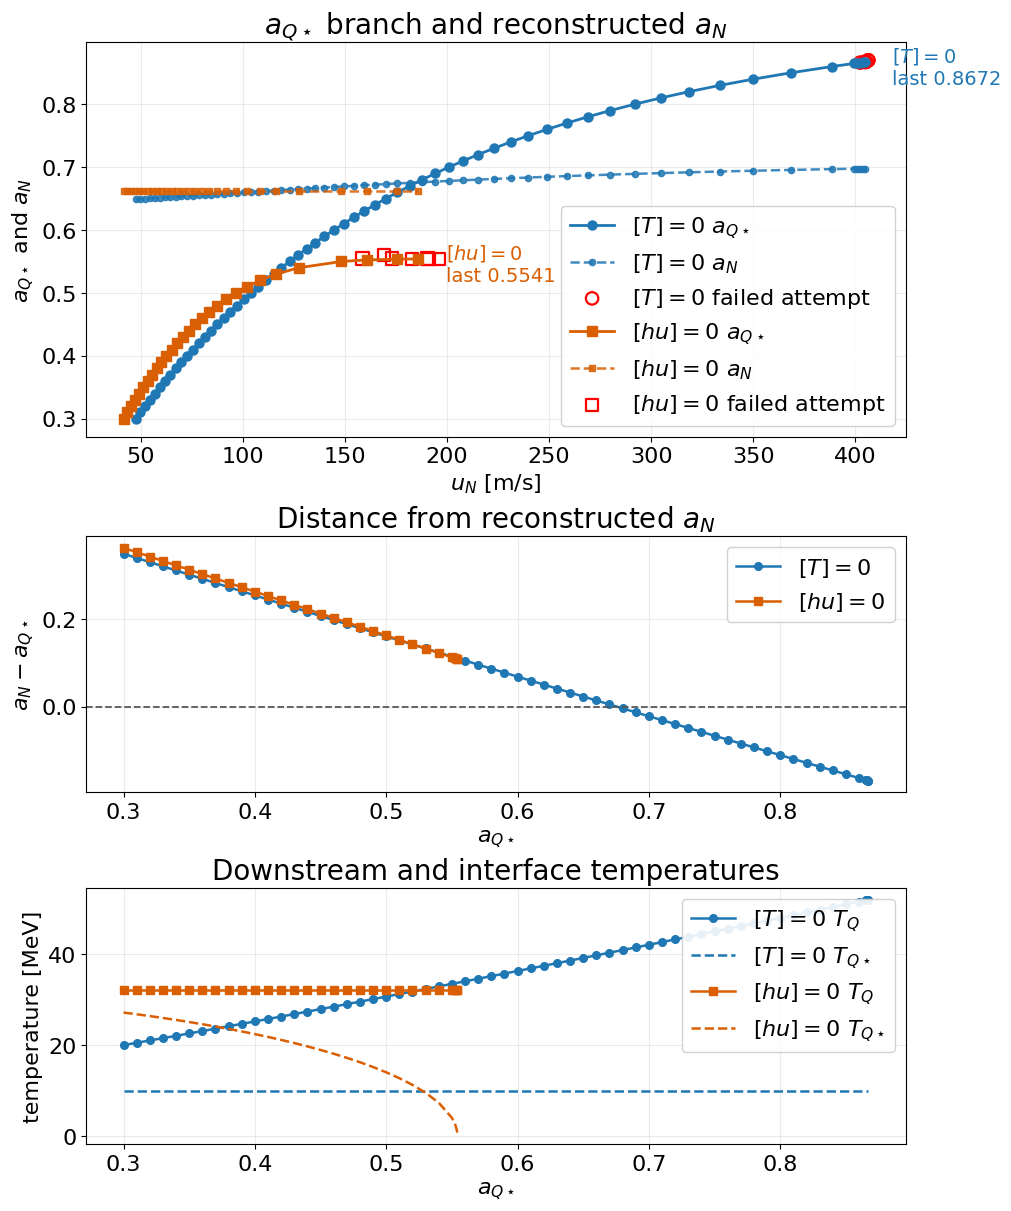

In [11]:
# VISUALIZE_A_QSTAR_UPPER_BOUND_TWO_MODE
# Compare T_const and hu_const adaptive continuation scans.

import numpy as np
import matplotlib.pyplot as plt

if 'aQstar_upper_bound_df' not in globals():
    raise RuntimeError('Run the calculation cell or LOAD_A_QSTAR_UPPER_BOUND_TWO_MODE_DATA first.')

plot_df = aQstar_upper_bound_df.copy()
mode_order = tuple(globals().get('aQstar_upper_bound_modes', tuple(plot_df['mode'].dropna().unique())))
mode_colors = {
    'T_const': '#1f77b4',
    'hu_const': '#d95f02',
}
mode_markers = {
    'T_const': 'o',
    'hu_const': 's',
}
mode_display_labels = {
    'T_const': r'$[T]=0$',
    'hu_const': r'$[hu]=0$',
}

TitleFont = 20
LabelFont = 16
TickFont = 16
LegendFont = 16

# Tune the first subplot legend here. Set main_legend_bbox = None for normal Matplotlib loc behavior.
main_legend_loc = 'best'
main_legend_bbox = None
main_legend_ncol = 1

fig, axes = plt.subplots(
    3, 1,
    figsize=(10.0, 12.0),
    constrained_layout=True,
    gridspec_kw={'height_ratios': [2, 1.3, 1.3]},
)
ax_main, ax_gap, ax_temp = axes

for mode in mode_order:
    mode_df = plot_df[plot_df['mode'] == mode].sort_values(['aQstar', 'success'])
    success_df = mode_df[mode_df['success'] & np.isfinite(mode_df['u_N_m_s'])]
    fail_df = mode_df[(~mode_df['success']) & np.isfinite(mode_df['u_N_plot_m_s'])]
    color = mode_colors.get(mode, '0.25')
    marker = mode_markers.get(mode, 'o')
    mode_label = mode_display_labels.get(mode, mode)

    if len(success_df):
        ax_main.plot(
            success_df['u_N_m_s'], success_df['aQstar'],
            color=color, marker=marker, ms=6.5, lw=2.0, label=fr'{mode_label} $a_{{Q\star}}$'
        )
        if 'a_N' in success_df:
            ax_main.plot(
                success_df['u_N_m_s'], success_df['a_N'],
                color=color, marker=marker, ms=4.5, lw=1.8, ls='--', alpha=0.85,
                label=fr'{mode_label} $a_N$'
            )
        last = success_df.iloc[-1]
        ax_main.annotate(
            f"{mode_label}\nlast {last['aQstar']:.4f}",
            xy=(last['u_N_m_s'], last['aQstar']),
            xytext=(20, -16),
            textcoords='offset points',
            fontsize=14,
            color=color,
        )

        ax_gap.plot(
            success_df['aQstar'], success_df['a_N_minus_aQstar'],
            color=color, marker=marker, ms=5.5, lw=1.8, label=mode_label
        )
        ax_temp.plot(success_df['aQstar'], success_df['T_Q'], color=color, marker=marker, ms=5.5, lw=1.8, label=f'{mode_label} $T_Q$')
        ax_temp.plot(success_df['aQstar'], success_df['T_Qstar'], color=color, ls='--', lw=1.8, label=fr'{mode_label} $T_{{Q\star}}$')

    if len(fail_df):
        ax_main.scatter(
            fail_df['u_N_plot_m_s'], fail_df['aQstar'],
            marker=marker, s=80, facecolors='none', edgecolors='red', linewidths=1.6,
            label=f'{mode_label} failed attempt'
        )

ax_main.set_title(r'$a_{Q\star}$ branch and reconstructed $a_N$', fontsize=TitleFont)
ax_main.set_xlabel(r'$u_N$ [m/s]', fontsize=LabelFont)
ax_main.set_ylabel(r'$a_{Q\star}$ and $a_N$', fontsize=LabelFont)

ax_gap.axhline(0.0, color='0.35', ls='--', lw=1.3)
ax_gap.set_title(r'Distance from reconstructed $a_N$', fontsize=TitleFont)
ax_gap.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_gap.set_ylabel(r'$a_N-a_{Q\star}$', fontsize=LabelFont)

ax_temp.set_title('Downstream and interface temperatures', fontsize=TitleFont)
ax_temp.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_temp.set_ylabel('temperature [MeV]', fontsize=LabelFont)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

main_handles, main_labels = ax_main.get_legend_handles_labels()
unique_main_handles = []
unique_main_labels = []
for handle, label in zip(main_handles, main_labels):
    if label not in unique_main_labels:
        unique_main_handles.append(handle)
        unique_main_labels.append(label)

main_legend_kwargs = dict(
    handles=unique_main_handles,
    labels=unique_main_labels,
    fontsize=LegendFont,
    loc=main_legend_loc,
    framealpha=0.90,
    ncol=main_legend_ncol,
)
if main_legend_bbox is not None:
    main_legend_kwargs['bbox_to_anchor'] = main_legend_bbox
ax_main.legend(**main_legend_kwargs)

ax_gap.legend(fontsize=LegendFont, loc='best', framealpha=0.90)
ax_temp.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

failed_rows = plot_df[~plot_df['success']]
if len(failed_rows):
    print('Failed attempts and diagnostic labels:')
    display(failed_rows[['mode', 'aQstar', 'failure_label', 'algebraic_ok', 'u_N_trial_m_s', 'algebraic_message', 'message']])

plt.savefig('aQstar_upper_bound_T10.pdf', bbox_inches='tight', dpi=300)
plt.show()
